In [1]:
pip install numpy pandas matplotlib seaborn scikit-learn tensorflow pillow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [3]:
# Sesuaikan path folder dataset Anda
train_dir = r"D:\potato-disease-leaf-datasetpld2\PLD_3_Classes_256\Training"
val_dir   = r"D:\potato-disease-leaf-datasetpld2\PLD_3_Classes_256\Validation"
test_dir  = r"D:\potato-disease-leaf-datasetpld2\PLD_3_Classes_256\Testing"

# Parameter Gambar & Training
IMG_HEIGHT = 150
IMG_WIDTH  = 150
BATCH_SIZE = 32
EPOCHS     = 25

In [4]:
# Augmentasi untuk data Training agar model tidak mudah overfitting
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Untuk Validation & Testing cukup lakukan rescaling (normalisasi piksel 0-1)
val_test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_generator = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

test_generator = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False  # Wajib False agar urutan prediksi sesuai dengan label asli saat evaluasi
)

# Menampilkan daftar kelas & mapping index
class_names = list(train_generator.class_indices.keys())
num_classes = len(class_names)

print("\nDaftar Kelas Dataset:", class_names)
print("Mapping Index:", train_generator.class_indices)

Found 3251 images belonging to 3 classes.
Found 416 images belonging to 3 classes.
Found 405 images belonging to 3 classes.

Daftar Kelas Dataset: ['Early_Blight', 'Healthy', 'Late_Blight']
Mapping Index: {'Early_Blight': 0, 'Healthy': 1, 'Late_Blight': 2}


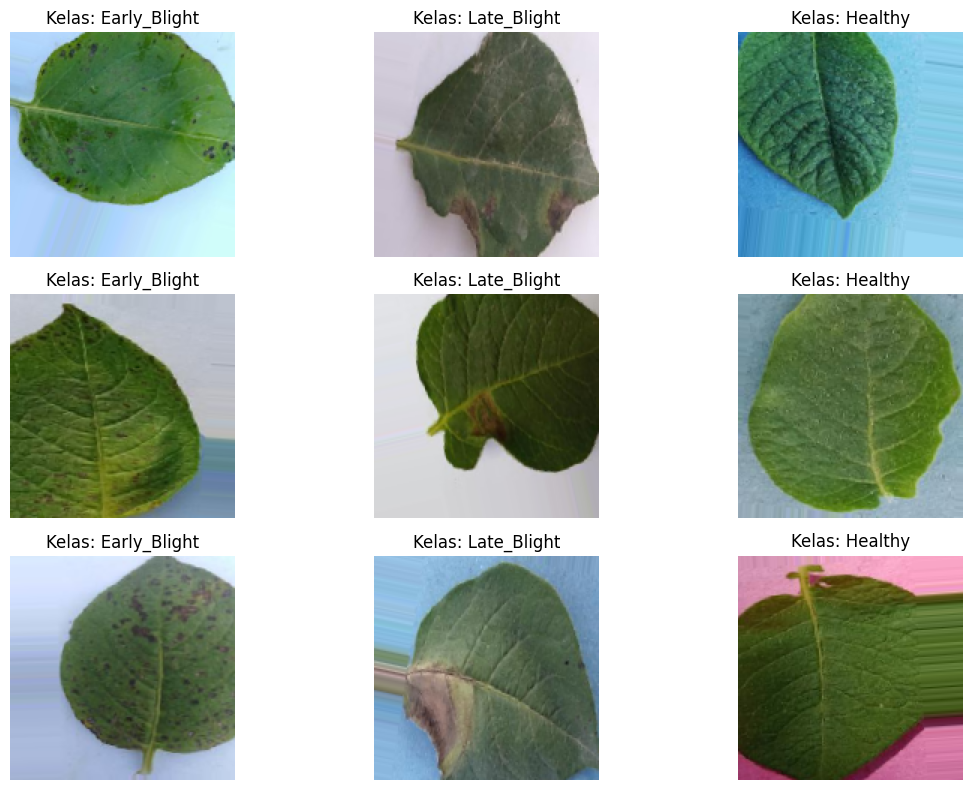

In [5]:
images, labels = next(train_generator)

plt.figure(figsize=(12, 8))
for i in range(min(9, len(images))):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i])
    label_idx = np.argmax(labels[i])
    plt.title(f"Kelas: {class_names[label_idx]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

In [6]:
model = Sequential([
    # Blok Konvolusi 1
    Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),

    # Blok Konvolusi 2
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),

    # Blok Konvolusi 3
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),

    # Blok Konvolusi 4
    Conv2D(256, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),

    # Flattening & Fully Connected Layer
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')  # Gunakan 'sigmoid' jika hanya 2 kelas dengan class_mode='binary'
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

C:\Users\user\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 37, 37, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 18, 18, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 20736)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     5,308,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,699,779 (21.74 MB)

 Trainable params: 5,698,819 (21.74 MB)

 Non-trainable params: 960 (3.75 KB)

In [7]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6, verbose=1),
    ModelCheckpoint('best_cnn_model.keras', monitor='val_accuracy', save_best_only=True, verbose=1)
]

history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator,
    callbacks=callbacks
)

Epoch 1/25
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4974 - loss: 2.5277
Epoch 1: val_accuracy improved from None to 0.24519, saving model to best_cnn_model.keras

Epoch 1: finished saving model to best_cnn_model.keras
102/102 ━━━━━━━━━━━━━━━━━━━━ 152s 1s/step - accuracy: 0.4974 - loss: 2.5277 - val_accuracy: 0.2452 - val_loss: 14.2818 - learning_rate: 0.0010
Epoch 2/25
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 971ms/step - accuracy: 0.5734 - loss: 0.9320
Epoch 2: val_accuracy did not improve from 0.24519
102/102 ━━━━━━━━━━━━━━━━━━━━ 101s 991ms/step - accuracy: 0.5734 - loss: 0.9320 - val_accuracy: 0.2452 - val_loss: 18.7532 - learning_rate: 0.0010
Epoch 3/25
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 955ms/step - accuracy: 0.6189 - loss: 0.8651
Epoch 3: val_accuracy did not improve from 0.24519
102/102 ━━━━━━━━━━━━━━━━━━━━ 100s 976ms/step - accuracy: 0.6189 - loss: 0.8651 - val_accuracy: 0.2452 - val_loss: 16.6152 - learning_rate: 0.0010
Epoch 4/25
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - acc

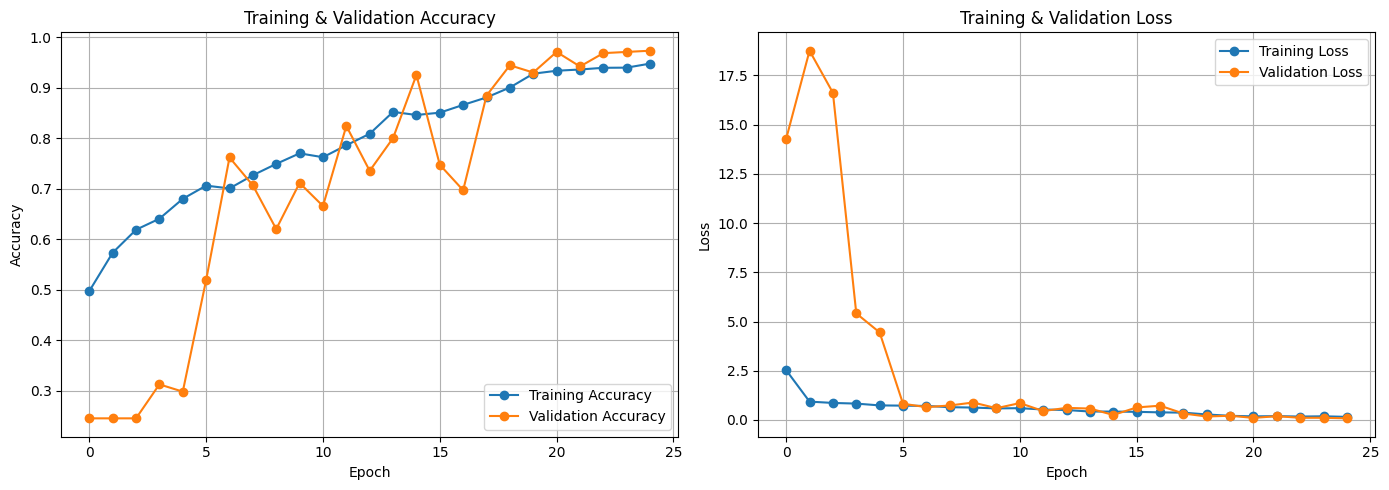

In [8]:
acc      = history.history['accuracy']
val_acc  = history.history['val_accuracy']
loss     = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(14, 5))

# Plot Akurasi
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', marker='o')
plt.plot(epochs_range, val_acc, label='Validation Accuracy', marker='o')
plt.title('Training & Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', marker='o')
plt.plot(epochs_range, val_loss, label='Validation Loss', marker='o')
plt.title('Training & Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
plt.show()

13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 298ms/step - accuracy: 0.9704 - loss: 0.1029

Test Loss     : 0.1029
Test Accuracy : 97.04%
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 141ms/step

=== Classification Report ===
              precision    recall  f1-score   support

Early_Blight       0.97      0.96      0.97       162
     Healthy       0.95      0.98      0.97       102
 Late_Blight       0.98      0.97      0.98       141

    accuracy                           0.97       405
   macro avg       0.97      0.97      0.97       405
weighted avg       0.97      0.97      0.97       405



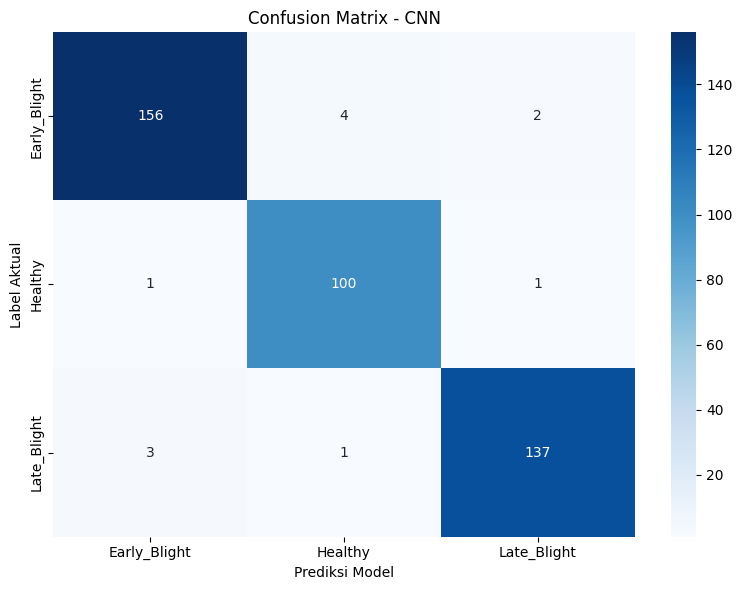

In [9]:
# Evaluasi loss & akurasi keseluruhan
test_loss, test_accuracy = model.evaluate(test_generator)
print(f"\nTest Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")

# Prediksi pada data testing
predictions = model.predict(test_generator)
y_pred = np.argmax(predictions, axis=1)
y_true = test_generator.classes

# Classification Report
print("\n=== Classification Report ===")
print(classification_report(y_true, y_pred, target_names=class_names))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - CNN')
plt.xlabel('Prediksi Model')
plt.ylabel('Label Aktual')
plt.tight_layout()
plt.show()

In [10]:
import json

# Simpan model final
model.save("model_klasifikasi_cnn.h5")

# Simpan mapping nama kelas agar urutan label saat prediksi di Streamlit tetap konsisten
with open("class_indices.json", "w") as f:
    json.dump(train_generator.class_indices, f)

print("Model dan class_indices.json berhasil disimpan!")

Model dan class_indices.json berhasil disimpan!
